In [2]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import os

# Project Path
project_path = r"C:\Users\Khushi\ML Internship\FUTURE_ML_03"

# Create Project Folders
data_path = os.path.join(project_path, "data")
outputs_path = os.path.join(project_path, "outputs")

os.makedirs(data_path, exist_ok=True)
os.makedirs(outputs_path, exist_ok=True)

print("Libraries Imported Successfully!")
print("Project Folders Created Successfully!")

Libraries Imported Successfully!
Project Folders Created Successfully!


In [3]:
data = {
    "Candidate_ID": range(1, 16),

    "Resume_Text": [
        "Python developer with skills in Python, SQL, Machine Learning and Pandas",
        "Java developer with skills in Java, Spring Boot and MySQL",
        "Data analyst skilled in Python, SQL, Excel and Power BI",
        "Machine Learning engineer with Python, Scikit-learn, Pandas and NumPy",
        "Web developer skilled in HTML, CSS, JavaScript and React",
        "Python developer with Flask, SQL, Machine Learning and Git",
        "Data scientist skilled in Python, Machine Learning, Deep Learning and NLP",
        "Software engineer with Java, Python, SQL and Git",
        "AI engineer skilled in Python, NLP, LLM, RAG and LangChain",
        "Fresher with Python, Pandas, NumPy and Machine Learning knowledge",
        "Backend developer skilled in Python, Django, SQL and REST API",
        "Data analyst with Excel, SQL, Tableau and Python",
        "ML engineer skilled in Python, TensorFlow, Scikit-learn and Deep Learning",
        "Frontend developer with HTML, CSS, JavaScript and Angular",
        "Python developer with Machine Learning, Flask, SQL and API integration"
    ],

    "Experience_Years": [2, 3, 1, 2, 4, 1, 3, 2, 1, 0, 2, 3, 2, 1, 2],

    "Education": [
        "B.Tech Computer Science", "BCA", "B.Sc Computer Science",
        "B.Tech IT", "B.Tech Computer Science", "BCA",
        "M.Tech Computer Science", "B.Tech IT", "B.Tech Computer Science",
        "B.Tech Computer Science", "BCA", "B.Com",
        "B.Tech Computer Science", "BCA", "B.Tech Computer Science"
    ]
}

df = pd.DataFrame(data)

df.head()

,Candidate_ID,Resume_Text,Experience_Years,Education
0,1,"Python developer with skills in Python, SQL, M...",2,B.Tech Computer Science
1,2,"Java developer with skills in Java, Spring Boo...",3,BCA
2,3,"Data analyst skilled in Python, SQL, Excel and...",1,B.Sc Computer Science
3,4,"Machine Learning engineer with Python, Scikit-...",2,B.Tech IT
4,5,"Web developer skilled in HTML, CSS, JavaScript...",4,B.Tech Computer Science


In [4]:
csv_path = os.path.join(data_path, "Resume_Dataset.csv")

df.to_csv(csv_path, index=False)

print("Dataset Saved Successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset Saved Successfully!
Dataset Shape: (15, 4)


,Candidate_ID,Resume_Text,Experience_Years,Education
0,1,"Python developer with skills in Python, SQL, M...",2,B.Tech Computer Science
1,2,"Java developer with skills in Java, Spring Boo...",3,BCA
2,3,"Data analyst skilled in Python, SQL, Excel and...",1,B.Sc Computer Science
3,4,"Machine Learning engineer with Python, Scikit-...",2,B.Tech IT
4,5,"Web developer skilled in HTML, CSS, JavaScript...",4,B.Tech Computer Science


In [5]:
job_description = """
We are looking for a Python Developer with knowledge of
Python, SQL, Machine Learning, Pandas, NumPy, Flask, Git and REST API.
The candidate should have good problem-solving skills.
"""

required_skills = [
    "Python",
    "SQL",
    "Machine Learning",
    "Pandas",
    "NumPy",
    "Flask",
    "Git",
    "REST API"
]

print("Job Description:")
print(job_description)

print("Required Skills:", required_skills)

Job Description:

We are looking for a Python Developer with knowledge of
Python, SQL, Machine Learning, Pandas, NumPy, Flask, Git and REST API.
The candidate should have good problem-solving skills.

Required Skills: ['Python', 'SQL', 'Machine Learning', 'Pandas', 'NumPy', 'Flask', 'Git', 'REST API']


In [6]:
skills_list = [
    "Python", "SQL", "Machine Learning", "Pandas", "NumPy",
    "Flask", "Git", "REST API", "Java", "Spring Boot",
    "MySQL", "Excel", "Power BI", "Scikit-learn",
    "HTML", "CSS", "JavaScript", "React", "Deep Learning",
    "NLP", "LLM", "RAG", "LangChain", "Django",
    "TensorFlow", "Tableau", "Angular"
]

def extract_skills(text):
    extracted = []

    for skill in skills_list:
        pattern = r"\b" + re.escape(skill) + r"\b"

        if re.search(pattern, text, re.IGNORECASE):
            extracted.append(skill)

    return extracted

df["Extracted_Skills"] = df["Resume_Text"].apply(extract_skills)

df[["Candidate_ID", "Resume_Text", "Extracted_Skills"]].head(10)

,Candidate_ID,Resume_Text,Extracted_Skills
0,1,"Python developer with skills in Python, SQL, M...","[Python, SQL, Machine Learning, Pandas]"
1,2,"Java developer with skills in Java, Spring Boo...","[Java, Spring Boot, MySQL]"
2,3,"Data analyst skilled in Python, SQL, Excel and...","[Python, SQL, Excel, Power BI]"
3,4,"Machine Learning engineer with Python, Scikit-...","[Python, Machine Learning, Pandas, NumPy, Scik..."
4,5,"Web developer skilled in HTML, CSS, JavaScript...","[HTML, CSS, JavaScript, React]"
5,6,"Python developer with Flask, SQL, Machine Lear...","[Python, SQL, Machine Learning, Flask, Git]"
6,7,"Data scientist skilled in Python, Machine Lear...","[Python, Machine Learning, Deep Learning, NLP]"
7,8,"Software engineer with Java, Python, SQL and Git","[Python, SQL, Git, Java]"
8,9,"AI engineer skilled in Python, NLP, LLM, RAG a...","[Python, NLP, LLM, RAG, LangChain]"
9,10,"Fresher with Python, Pandas, NumPy and Machine...","[Python, Machine Learning, Pandas, NumPy]"


In [7]:
def calculate_match_score(candidate_skills):
    matched_skills = [
        skill for skill in required_skills
        if skill in candidate_skills
    ]

    score = (len(matched_skills) / len(required_skills)) * 100

    return score

df["Match_Score"] = df["Extracted_Skills"].apply(calculate_match_score)

df[["Candidate_ID", "Extracted_Skills", "Match_Score"]].head(10)

,Candidate_ID,Extracted_Skills,Match_Score
0,1,"[Python, SQL, Machine Learning, Pandas]",50.0
1,2,"[Java, Spring Boot, MySQL]",0.0
2,3,"[Python, SQL, Excel, Power BI]",25.0
3,4,"[Python, Machine Learning, Pandas, NumPy, Scik...",50.0
4,5,"[HTML, CSS, JavaScript, React]",0.0
5,6,"[Python, SQL, Machine Learning, Flask, Git]",62.5
6,7,"[Python, Machine Learning, Deep Learning, NLP]",25.0
7,8,"[Python, SQL, Git, Java]",37.5
8,9,"[Python, NLP, LLM, RAG, LangChain]",12.5
9,10,"[Python, Machine Learning, Pandas, NumPy]",50.0


In [8]:
df = df.sort_values(by="Match_Score", ascending=False)

df["Rank"] = range(1, len(df) + 1)

df[["Rank", "Candidate_ID", "Match_Score"]]

,Rank,Candidate_ID,Match_Score
5,1,6,62.5
3,2,4,50.0
0,3,1,50.0
14,4,15,50.0
9,5,10,50.0
7,6,8,37.5
10,7,11,37.5
11,8,12,25.0
6,9,7,25.0
2,10,3,25.0


In [9]:
def find_missing_skills(candidate_skills):
    missing = [
        skill for skill in required_skills
        if skill not in candidate_skills
    ]

    return missing

df["Missing_Skills"] = df["Extracted_Skills"].apply(find_missing_skills)

df[["Candidate_ID", "Match_Score", "Extracted_Skills", "Missing_Skills"]].head(10)

,Candidate_ID,Match_Score,Extracted_Skills,Missing_Skills
5,6,62.5,"[Python, SQL, Machine Learning, Flask, Git]","[Pandas, NumPy, REST API]"
3,4,50.0,"[Python, Machine Learning, Pandas, NumPy, Scik...","[SQL, Flask, Git, REST API]"
0,1,50.0,"[Python, SQL, Machine Learning, Pandas]","[NumPy, Flask, Git, REST API]"
14,15,50.0,"[Python, SQL, Machine Learning, Flask]","[Pandas, NumPy, Git, REST API]"
9,10,50.0,"[Python, Machine Learning, Pandas, NumPy]","[SQL, Flask, Git, REST API]"
7,8,37.5,"[Python, SQL, Git, Java]","[Machine Learning, Pandas, NumPy, Flask, REST ..."
10,11,37.5,"[Python, SQL, REST API, Django]","[Machine Learning, Pandas, NumPy, Flask, Git]"
11,12,25.0,"[Python, SQL, Excel, Tableau]","[Machine Learning, Pandas, NumPy, Flask, Git, ..."
6,7,25.0,"[Python, Machine Learning, Deep Learning, NLP]","[SQL, Pandas, NumPy, Flask, Git, REST API]"
2,3,25.0,"[Python, SQL, Excel, Power BI]","[Machine Learning, Pandas, NumPy, Flask, Git, ..."


In [10]:
screening_report = df[
    [
        "Rank",
        "Candidate_ID",
        "Experience_Years",
        "Education",
        "Extracted_Skills",
        "Match_Score",
        "Missing_Skills"
    ]
].copy()

screening_report

,Rank,Candidate_ID,Experience_Years,Education,Extracted_Skills,Match_Score,Missing_Skills
5,1,6,1,BCA,"[Python, SQL, Machine Learning, Flask, Git]",62.5,"[Pandas, NumPy, REST API]"
3,2,4,2,B.Tech IT,"[Python, Machine Learning, Pandas, NumPy, Scik...",50.0,"[SQL, Flask, Git, REST API]"
0,3,1,2,B.Tech Computer Science,"[Python, SQL, Machine Learning, Pandas]",50.0,"[NumPy, Flask, Git, REST API]"
14,4,15,2,B.Tech Computer Science,"[Python, SQL, Machine Learning, Flask]",50.0,"[Pandas, NumPy, Git, REST API]"
9,5,10,0,B.Tech Computer Science,"[Python, Machine Learning, Pandas, NumPy]",50.0,"[SQL, Flask, Git, REST API]"
7,6,8,2,B.Tech IT,"[Python, SQL, Git, Java]",37.5,"[Machine Learning, Pandas, NumPy, Flask, REST ..."
10,7,11,2,BCA,"[Python, SQL, REST API, Django]",37.5,"[Machine Learning, Pandas, NumPy, Flask, Git]"
11,8,12,3,B.Com,"[Python, SQL, Excel, Tableau]",25.0,"[Machine Learning, Pandas, NumPy, Flask, Git, ..."
6,9,7,3,M.Tech Computer Science,"[Python, Machine Learning, Deep Learning, NLP]",25.0,"[SQL, Pandas, NumPy, Flask, Git, REST API]"
2,10,3,1,B.Sc Computer Science,"[Python, SQL, Excel, Power BI]",25.0,"[Machine Learning, Pandas, NumPy, Flask, Git, ..."


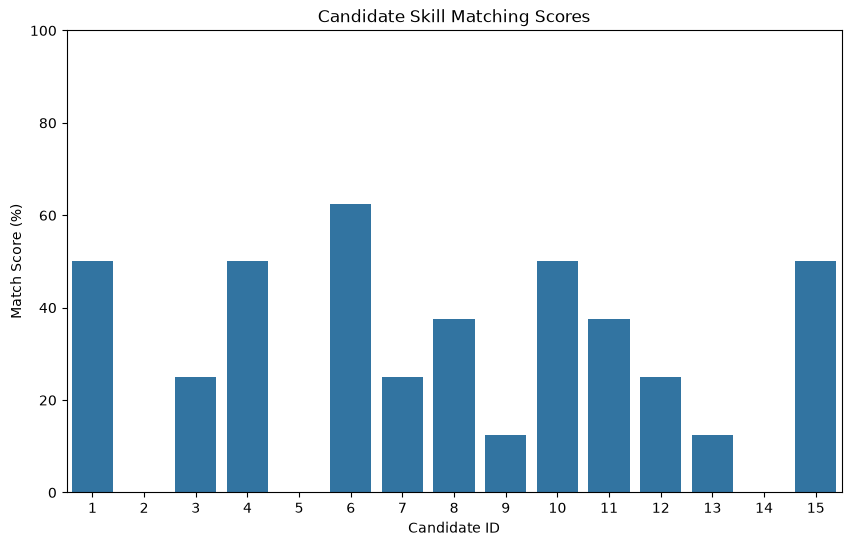

In [11]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=df,
    x="Candidate_ID",
    y="Match_Score"
)

plt.title("Candidate Skill Matching Scores")
plt.xlabel("Candidate ID")
plt.ylabel("Match Score (%)")
plt.ylim(0, 100)
plt.show()

In [12]:
report_path = os.path.join(
    outputs_path,
    "Candidate_Screening_Report.csv"
)

screening_report.to_csv(report_path, index=False)

print("Candidate Screening Report Saved Successfully!")
print("File Location:", report_path)

Candidate Screening Report Saved Successfully!
File Location: C:\Users\Khushi\ML Internship\FUTURE_ML_03\outputs\Candidate_Screening_Report.csv


In [13]:
print("Data Folder:", os.listdir(data_path))
print("Outputs Folder:", os.listdir(outputs_path))

Data Folder: ['Resume_Dataset.csv']
Outputs Folder: ['Candidate_Screening_Report.csv']
